# 00 — Scope & Environment

Notebook này xác định phạm vi bài toán, môi trường thực thi,
đặc điểm dữ liệu đầu vào và các giới hạn tài nguyên trước khi
triển khai pipeline Machine Learning.

Mục tiêu:
- Xác định rõ bài toán và target.
- Ghi nhận môi trường thực thi.
- Khảo sát kích thước và schema của raw datasets.
- Đánh giá khả năng xử lý dữ liệu theo tài nguyên hiện có.
- Đưa ra các quyết định kỹ thuật ban đầu cho pipeline.

## 1. Project Scope

Xác định phạm vi bài toán trước khi thực hiện EDA và
feature engineering.

In [2]:
PROJECT_NAME = "Machine Learning Final Project"
DATA_DIR = "../data"
RAW_DATA_DIR = "../data/raw"

TARGET_COLUMN = "unit_sales"

TASK_TYPE = "Time Series Forecasting"

print(f"Project: {PROJECT_NAME}")
print(f"Task: {TASK_TYPE}")
print(f"Target: {TARGET_COLUMN}")
print(f"Raw data directory: {RAW_DATA_DIR}")

Project: Machine Learning Final Project
Task: Time Series Forecasting
Target: unit_sales
Raw data directory: ../data/raw


### Scope Notes

- Bài toán được xác định là dự báo doanh số.
- Target ban đầu dự kiến là `unit_sales`.
- Raw datasets được lưu tại `data/raw/`.
- Các quyết định về feature và validation sẽ được xác định
  sau khi hoàn thành data validation.

  -> Chưa chốt nếu thông tin chưa chắc chắn

### 1.1 Problem statement & forecast horizon

| Thành phần | Nội dung | Trạng thái |
|---|---|---|
| Bài toán | Dự báo doanh số bán lẻ (Corporación Favorita, Ecuador) | Đã xác nhận |
| Đơn vị dự báo (granularity) | `(date, store_nbr, item_nbr)` | Đã xác nhận từ `test.csv` |
| Target | `unit_sales` (số lượng; có thể là số thực với hàng bán theo kg; âm = trả hàng) | Đã xác nhận ở 01 |
| Horizon | Các ngày trong `test.csv` (được kiểm tra bằng code bên dưới) | Kiểm tra bằng code |
| Điểm cắt (forecast origin) | Ngày cuối cùng của `train.csv` | Kiểm tra ở 01 |
| Đầu ra cuối | `sample_submission.csv`: `id`, `unit_sales` | Đã xác nhận |

Cell dưới đây kiểm tra horizon và độ phủ của `test.csv` thay vì ghi cứng các con số.

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")

test_keys = pd.read_csv(
    RAW_DATA_DIR / "test.csv",
    usecols=["date", "store_nbr", "item_nbr"],
    dtype={"date": "string", "store_nbr": "int16", "item_nbr": "int32"},
)
test_dates = pd.to_datetime(test_keys["date"])

FORECAST_START = test_dates.min()
FORECAST_END = test_dates.max()
FORECAST_HORIZON_DAYS = int(test_dates.nunique())
EXPECTED_TRAIN_END = FORECAST_START - pd.Timedelta(days=1)

n_pairs_test = len(test_keys[["store_nbr", "item_nbr"]].drop_duplicates())
is_full_grid = (n_pairs_test * FORECAST_HORIZON_DAYS) == len(test_keys)
is_contiguous = (FORECAST_END - FORECAST_START).days + 1 == FORECAST_HORIZON_DAYS

horizon_summary = pd.Series({
    "forecast_start": FORECAST_START.date(),
    "forecast_end": FORECAST_END.date(),
    "horizon_days": FORECAST_HORIZON_DAYS,
    "expected_train_end (start - 1 day)": EXPECTED_TRAIN_END.date(),
    "test_rows": len(test_keys),
    "unique_store_item_pairs": n_pairs_test,
    "test_is_full_pair_x_day_grid": is_full_grid,
    "test_dates_contiguous": is_contiguous,
    "unique_stores": test_keys["store_nbr"].nunique(),
    "unique_items": test_keys["item_nbr"].nunique(),
})
display(horizon_summary.to_frame("value"))

del test_keys, test_dates

,value
forecast_start,2017-08-16
forecast_end,2017-08-31
horizon_days,16
expected_train_end (start - 1 day),2017-08-15
test_rows,3370464
unique_store_item_pairs,210654
test_is_full_pair_x_day_grid,True
test_dates_contiguous,True
unique_stores,54
unique_items,3901


**Ghi chú về horizon (dựa trên dữ liệu thực tế của bạn):**

- `test.csv` có 3.370.464 dòng = 210.654 cặp (store, item) × 16 ngày (16/08/2017 → 31/08/2017), nên là một **lưới đầy đủ** theo cặp × ngày.
- `train.csv` ở notebook 01 **không có dòng nào có `unit_sales = 0`** (zero_count = 0), nghĩa là các ngày không bán được thường **không được ghi dòng** (*implicit zeros*). Test lại yêu cầu dự báo cho mọi ngày của mọi cặp, nên mô hình phải học được xác suất "không bán" chứ không chỉ mức bán khi có bán. Đây là quyết định quan trọng cho notebook feature engineering (xem mục 7.9 của notebook 01).
- Horizon 16 ngày liên tiếp ngay sau ngày cuối của train → validation nên mô phỏng đúng cấu trúc này (16 ngày cuối của train làm validation; có thể thêm một fold cùng thời điểm mùa vụ năm trước).

### 1.2 Evaluation metric

Theo mô tả của cuộc thi Kaggle *Corporación Favorita Grocery Sales Forecasting* (cần đối chiếu với yêu cầu đề tài của bạn nếu thầy/cô quy định metric khác), điểm số là **NWRMSLE** (Normalized Weighted Root Mean Squared Logarithmic Error):

$$
\text{NWRMSLE} = \sqrt{\frac{\sum_i w_i \left(\ln(\hat y_i + 1) - \ln(y_i + 1)\right)^2}{\sum_i w_i}}
$$

- `w_i = 1.25` nếu mặt hàng `perishable = 1`, ngược lại `w_i = 1.00`.
- Giá trị `unit_sales` âm (trả hàng) được xử lý như `0` khi chấm điểm → **không cần xóa dòng âm ở cleaning; chỉ cần clip khi tính metric/huấn luyện**.
- Hệ quả: sai số được đo trên thang `log1p`, nên mô hình nên được huấn luyện trên `log1p(clip(unit_sales, 0))` (RMSE trên thang log tương đương metric) và các mặt hàng perishable quan trọng hơn 25%.

In [4]:
import numpy as np

PERISHABLE_WEIGHT = 1.25
NON_PERISHABLE_WEIGHT = 1.00


def nwrmsle(y_true, y_pred, perishable,
            perishable_weight=PERISHABLE_WEIGHT,
            non_perishable_weight=NON_PERISHABLE_WEIGHT):
    """Normalized Weighted RMSLE. Giá trị âm của y_true và y_pred được clip về 0."""
    y_true = np.clip(np.asarray(y_true, dtype="float64"), 0, None)
    y_pred = np.clip(np.asarray(y_pred, dtype="float64"), 0, None)
    weights = np.where(np.asarray(perishable) == 1, perishable_weight, non_perishable_weight)

    squared_log_error = (np.log1p(y_pred) - np.log1p(y_true)) ** 2
    return float(np.sqrt(np.sum(weights * squared_log_error) / np.sum(weights)))


# --- Kiểm thử hàm metric trên các trường hợp tính tay được ---
assert nwrmsle([0, 3, 10], [0, 3, 10], [0, 1, 0]) == 0.0

# Một điểm, không perishable: sqrt((ln4 - ln2)^2) = ln 2
assert abs(nwrmsle([1], [3], [0]) - np.log(2)) < 1e-12

# Giá trị âm của y_true được coi là 0
assert abs(nwrmsle([-5], [0], [0])) < 1e-12

# Trọng số: hai điểm, sai số log lần lượt a (perishable, w=1.25) và b (w=1)
a, b = np.log(2), np.log(3)
expected = np.sqrt((1.25 * a**2 + 1.0 * b**2) / (1.25 + 1.0))
assert abs(nwrmsle([1, 2], [3, 8], [1, 0]) - expected) < 1e-12

print("nwrmsle(): các kiểm thử cơ bản đều PASS")

nwrmsle(): các kiểm thử cơ bản đều PASS


**Baseline cần có trước khi huấn luyện mô hình** (để biết mô hình học được gì so với cách đơn giản):

| Baseline | Ý tưởng | Ghi chú |
|---|---|---|
| B0 | Dự báo hằng số (ví dụ trung vị toàn cục) | Mốc dưới cùng |
| B1 | Giá trị bán gần nhất của cặp (store, item) | Naive |
| B2 | Trung bình `log1p(unit_sales)` của cặp trong N ngày cuối (N = 7, 14, 28) | Tính lại theo từng fold |
| B3 | Như B2 nhưng theo từng thứ trong tuần | Bắt weekly seasonality |
| B4 | Cặp cold-start: dùng trung bình item hoặc store/class | Xem mục cold-start ở 01 |

Các baseline này sẽ được cài đặt ở notebook modeling; ghi ở đây để mọi quyết định sau đều có mốc so sánh.

### 1.3 Data dictionary (mức schema)

Các số liệu bên dưới lấy từ kết quả bạn đã chạy ở notebook 00 và 01.

| Bảng | Cột | Kiểu đọc mặc định | Ý nghĩa | Quan sát đã xác nhận |
|---|---|---|---|---|
| `train.csv` | `id` | int64 | Mã dòng | 125.497.040 dòng; kiểm tra tính liên tục ở 02 |
| | `date` | str | Ngày giao dịch | 2013-01-01 → 2017-08-15; 1.684 ngày duy nhất; thiếu 25/12 mỗi năm |
| | `store_nbr` | int64 | Mã cửa hàng | 54 cửa hàng, đều có trong `stores.csv` |
| | `item_nbr` | int64 | Mã mặt hàng | 4.036 mặt hàng, đều có trong `items.csv` |
| | `unit_sales` | float64 | Số lượng bán (âm = trả hàng) | 7.795 dòng âm (0,0062%), min −15.372, max 89.440, **không có dòng bằng 0** |
| | `onpromotion` | float64 (có NaN) | Mặt hàng có khuyến mãi hay không | Thiếu 17,26%; **thiếu 100% đến 2014-03, 0% từ 2014-04** |
| `test.csv` | `id, date, store_nbr, item_nbr, onpromotion` | | Lưới cặp × ngày cần dự báo | 16/08/2017 → 31/08/2017; `onpromotion` không thiếu |
| `sample_submission.csv` | `id, unit_sales` | | Mẫu nộp bài | `unit_sales` = 0 toàn bộ (không mang ý nghĩa dự báo) |
| `stores.csv` | `store_nbr, city, state, type, cluster` | | Thông tin cửa hàng | 54 dòng, không thiếu; type A–E |
| `items.csv` | `item_nbr, family, class, perishable` | | Thông tin mặt hàng | 4.100 dòng, 986 perishable (24%) |
| `oil.csv` | `date, dcoilwtico` | | Giá dầu WTI theo ngày giao dịch | 1.218 dòng, thiếu 43 giá trị (3,5%) |
| `holidays_events.csv` | `date, type, locale, locale_name, description, transferred` | | Ngày lễ/sự kiện | 350 dòng; 12 dòng `transferred = True` |
| `transactions.csv` | `date, store_nbr, transactions` | | Số giao dịch theo cửa hàng-ngày | 83.488 dòng; kết thúc 2017-08-15 |

### 1.4 Quan hệ giữa các bảng

```
                           stores.csv                    items.csv
                        (store_nbr PK)                (item_nbr PK)
                         city,state,type,cluster      family,class,perishable
                               ^                            ^
                               | store_nbr                  | item_nbr
   oil.csv ----date---->  train.csv / test.csv  <----date---- holidays_events.csv
 (date PK, trading days)  (date, store_nbr, item_nbr)         (nhiều dòng/ngày;
                                ^                              join theo locale:
                                | (date, store_nbr)            National / Regional(state) / Local(city))
                         transactions.csv
                       (date, store_nbr PK) — chỉ có đến 2017-08-15
```

Lưu ý khi join:

- `holidays_events` **không** có khóa duy nhất theo `date`; join theo `locale`: *National* áp dụng toàn quốc, *Regional* khớp với `stores.state`, *Local* khớp với `stores.city`.
- Với dòng `transferred = True`, ngày lễ gốc thực tế **không** được nghỉ; ngày thực sự nghỉ nằm ở dòng `type = Transfer`.
- `oil.csv` chỉ có ngày giao dịch (không có cuối tuần/ngày lễ) → cần quyết định cách điền khi tạo feature (để notebook 03).

### 1.5 Tính khả dụng của thông tin tại thời điểm dự báo (chống leakage)

Tại ngày cắt 15/08/2017, các nguồn dữ liệu sau đây có hoặc không có sẵn cho 16 ngày cần dự báo:

| Nguồn | Biết trước cho ngày tương lai? | Cách dùng an toàn |
|---|---|---|
| Lịch (thứ, ngày trong tháng, tháng) | Có | Dùng trực tiếp |
| `holidays_events` | Có (lịch lễ công bố trước) | Dùng trực tiếp, xử lý `transferred` |
| `onpromotion` trong `test.csv` | Có (được cung cấp) | Dùng trực tiếp; **chỉ tin cậy từ 2014-04 trở đi ở train** |
| `stores`, `items` | Có | Dùng trực tiếp |
| `unit_sales` | **Không** | Chỉ dùng giá trị lag ≥ khoảng cách tới ngày cắt |
| `transactions` | **Không** (kết thúc 2017-08-15) | Chỉ dùng dạng lag/rolling đã biết tại ngày cắt |
| `dcoilwtico` | Không nên giả định biết | Dùng lag hoặc giá trị tại ngày cắt |

Quy tắc: mọi feature của dòng ngày `t` trong horizon phải chỉ dùng thông tin có thể biết tại **ngày cắt**, không phải tại ngày `t`.

### 1.6 Quy ước dự án & pipeline notebook

```
project/
├── data/
│   ├── raw/          # chỉ đọc — không sửa, không ghi đè
│   ├── interim/      # cache tổng hợp phục vụ EDA (01)
│   └── processed/    # dữ liệu đã làm sạch (02) và feature (03)
├── notebooks/
│   ├── 00_scope_and_environment.ipynb   -> phạm vi, metric, tài nguyên, quyết định kỹ thuật ban đầu
│   ├── 01_eda.ipynb                     -> validation + khám phá dữ liệu
│   ├── 02_data_cleaning.ipynb           -> chuẩn hóa có kiểm soát, bảo toàn số dòng
│   └── 03_feature_engineering.ipynb     -> (tiếp theo) imputing theo thời gian, lag/rolling, calendar
└── reports/          # báo cáo JSON/CSV sinh từ các notebook
```

Quy ước chung: (1) raw là read-only; (2) seed cố định `SEED = 42`; (3) mọi quyết định dạng *provisional* phải ghi rõ để cập nhật; (4) mọi con số trong kết luận phải truy được tới một cell đã chạy.

### 1.7 Giả định, câu hỏi mở và rủi ro

| # | Mục | Mức độ | Hành động |
|---|---|---|---|
| R1 | Metric chính thức có đúng NWRMSLE không? | Cao | Đối chiếu với đề bài trước khi tối ưu mô hình |
| R2 | Implicit zeros: train thưa, test là lưới đầy đủ | Cao | Quyết định cách dựng panel đầy đủ ở notebook 03 |
| R3 | 21,1% cặp (store, item) trong test chưa từng xuất hiện trong train | Cao | Chiến lược cold-start dựa trên item/store/class |
| R4 | `onpromotion` thiếu có cấu trúc (trước 2014-04) | Trung bình | Không impute giá trị `False` toàn cục; cân nhắc cửa sổ huấn luyện từ 2014-04 |
| R5 | RAM khả dụng chỉ ≈ 1.5–3.2 GB, không có GPU | Cao | Chunk/Parquet; mô hình chạy CPU; kiểm soát bản sao trung gian |
| R6 | Leakage từ `transactions` và `dcoilwtico` | Cao | Chỉ dùng lag đã biết tại ngày cắt |
| R7 | Đổi mức (level shift) và mật độ ghi dòng thay đổi theo thời gian (đặc biệt 2014) | Trung bình | Kiểm tra ở 7.9 (notebook 01) trước khi chọn cửa sổ huấn luyện |

### 1.8 Cập nhật sau khi hoàn thành notebook 01 và 02

Các rủi ro ở 1.7 đã được kiểm chứng bằng dữ liệu thật:

| # | Kết quả đã xác nhận | Nơi xem |
|---|---|---|
| R2 | Train phủ 34,2% lưới cặp × ngày; trong cửa sổ hoạt động chỉ 66,4% ngày có dòng; test là lưới đầy đủ 210.654 cặp × 16 ngày | 01, mục 7.9 |
| R3 | Cặp trong test: 71,07% cặp cũ còn bán, 19,56% cặp mới có item đã biết, 7,84% cặp cũ ngừng bán > 28 ngày, 1,54% item chưa từng có | 01, mục 7.16 |
| R4 | `onpromotion` thiếu có cấu trúc: dòng thiếu cuối cùng 2014-03-31, dòng có giá trị đầu tiên 2014-04-01 | 02, mục 4.1 |
| R6 | Tương quan giá dầu −0,437 → +0,076 sau khi khử xu hướng; `transactions` giữ 0,61 nhưng không biết trước | 01, mục 7.17 |
| R7 | Tổng doanh số tháng tương quan 0,965 với số dòng ghi nhận: xu hướng và cú đổi mức chủ yếu do độ phủ | 01, mục 7.9 |

**R1 (metric)** vẫn là giả định cần đối chiếu đề bài. **R5 (tài nguyên)** được xác nhận ở chiều bất lợi: lúc chạy notebook 01 RAM khả dụng chỉ khoảng 0,94 GB (87,4% đang dùng). Hãy đọc kết quả benchmark ở 4.2 để chọn `CHUNK_SIZE` và đóng các ứng dụng khác khi chạy các bước nặng.

**Trạng thái notebook này:** các cell mới (mục 1.1–1.7, 2.1, 4.1–4.3, 5.2) cần được chạy lại trên máy của bạn để có output (benchmark chunk-size, snapshot JSON `reports/00_environment_snapshot.json`).

## 2. Runtime Environment

Ghi nhận môi trường phần cứng và phần mềm hiện tại để xác định
các giới hạn tài nguyên có thể ảnh hưởng đến quá trình xử lý dữ liệu
và huấn luyện mô hình.

In [5]:
import os
import platform
import sys

print("Operating System:", platform.platform())
print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

Operating System: Linux-7.0.0-30-generic-x86_64-with-glibc2.39
Python Version: 3.11.16 (main, Aug 27 2026, 14:44:21) [GCC 14.3.0]
Python Executable: /home/phat/miniconda3/envs/grocery_env/bin/python


### Environment Notes

Kết quả trên được sử dụng để ghi nhận môi trường thực thi của project.

In [6]:
import os
import platform

print("CPU:", platform.processor())
print("Logical CPU cores:", os.cpu_count())

CPU: x86_64
Logical CPU cores: 8


### CPU Notes

Ghi nhận số logical CPU cores để làm cơ sở cân nhắc mức độ
parallelism trong các bước preprocessing và training.

In [7]:
import psutil

memory = psutil.virtual_memory()

print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"Used RAM: {memory.used / (1024**3):.2f} GB")
print(f"RAM Usage: {memory.percent:.1f}%")

Total RAM: 7.50 GB
Available RAM: 1.86 GB
Used RAM: 5.64 GB
RAM Usage: 75.2%


### RAM Notes

RAM khả dụng là một trong những yếu tố chính quyết định cách
đọc và xử lý các dataset lớn.

Kết quả sẽ được sử dụng ở phần Resource Assessment để quyết định
có cần chunking, dtype optimization hoặc các chiến lược giảm
memory usage hay không.

In [8]:
import shutil
import subprocess

gpu_available = shutil.which("nvidia-smi") is not None

if gpu_available:
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True,
        text=True
    )
    print(result.stdout.strip())
else:
    print("NVIDIA GPU: Not detected")

NVIDIA GPU: Not detected


### GPU Notes

Nếu không có GPU, việc lựa chọn mô hình và cấu hình training
sẽ ưu tiên các phương pháp có khả năng chạy hiệu quả trên CPU.

Nếu có GPU, thông tin VRAM sẽ được sử dụng để đánh giá khả năng
huấn luyện các mô hình có hỗ trợ GPU.

In [9]:
import shutil

disk = shutil.disk_usage(".")

print(f"Total disk: {disk.total / (1024**3):.2f} GB")
print(f"Used disk: {disk.used / (1024**3):.2f} GB")
print(f"Free disk: {disk.free / (1024**3):.2f} GB")

Total disk: 233.18 GB
Used disk: 122.76 GB
Free disk: 98.50 GB


### 2.1 Software stack & reproducibility

Ghi nhận phiên bản thư viện và cố định random seed để kết quả có thể tái lập.

In [10]:
import os
import random
import platform
from importlib import metadata

import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ.setdefault("PYTHONHASHSEED", str(SEED))

LIBRARIES = [
    "pandas", "numpy", "pyarrow", "matplotlib", "scipy", "scikit-learn",
    "statsmodels", "lightgbm", "xgboost", "catboost", "polars", "duckdb", "psutil",
]

library_versions = {}
for name in LIBRARIES:
    try:
        library_versions[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        library_versions[name] = None

versions_df = pd.DataFrame(
    {"package": list(library_versions), "version": [v or "not installed" for v in library_versions.values()]}
)
display(versions_df)
print("Python:", platform.python_version(), "| SEED =", SEED)

,package,version
0,pandas,3.0.5
1,numpy,2.4.6
2,pyarrow,25.0.1
3,matplotlib,3.11.2
4,scipy,1.17.1
5,scikit-learn,1.9.1
6,statsmodels,not installed
7,lightgbm,4.7.0
8,xgboost,3.2.0
9,catboost,not installed


Python: 3.11.16 | SEED = 42


## 3. Dataset Inventory

Khảo sát toàn bộ dữ liệu trong `data/raw/` mà không thay đổi
nội dung của raw datasets.

Các thông tin cần thu thập:

- File name
- File size
- Number of rows
- Number of columns
- Column names
- Data types

In [11]:
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")

csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))

print(f"Found {len(csv_files)} CSV files:\n")

for path in csv_files:
    print(path.name)

Found 8 CSV files:

holidays_events.csv
items.csv
oil.csv
sample_submission.csv
stores.csv
test.csv
train.csv
transactions.csv


In [12]:
import pandas as pd

file_inventory = []

for path in csv_files:
    file_inventory.append({
        "file": path.name,
        "size_mb": path.stat().st_size / (1024**2)
    })

file_inventory_df = (
    pd.DataFrame(file_inventory)
    .sort_values("size_mb", ascending=False)
    .reset_index(drop=True)
)

file_inventory_df

,file,size_mb
0,train.csv,4765.941895
1,test.csv,120.318438
2,sample_submission.csv,38.571913
3,transactions.csv,1.480710
4,items.csv,0.097123
5,holidays_events.csv,0.021276
6,oil.csv,0.019627
7,stores.csv,0.001323


### File Size Notes

Bảng trên cho phép xác định các raw datasets có kích thước lớn
nhất và là cơ sở ban đầu để đánh giá nguy cơ memory bottleneck.

In [13]:
dataset_summary = []

for path in csv_files:
    header = pd.read_csv(path, nrows=0)

    with open(path, "rb") as f:
        row_count = sum(1 for _ in f) - 1

    dataset_summary.append({
        "file": path.name,
        "rows": row_count,
        "columns": len(header.columns),
    })

dataset_summary_df = (
    pd.DataFrame(dataset_summary)
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

dataset_summary_df

,file,rows,columns
0,train.csv,125497040,6
1,sample_submission.csv,3370464,2
2,test.csv,3370464,5
3,transactions.csv,83488,3
4,items.csv,4100,4
5,oil.csv,1218,2
6,holidays_events.csv,350,6
7,stores.csv,54,5


In [14]:
schema_summary = {}

for path in csv_files:
    df_sample = pd.read_csv(path, nrows=1000)

    schema_summary[path.name] = pd.DataFrame({
        "column": df_sample.columns,
        "dtype": df_sample.dtypes.astype(str).values,
        "sample_memory_mb": [
            df_sample[[col]].memory_usage(deep=True).sum() / (1024**2)
            for col in df_sample.columns
        ]
    })

for filename, schema in schema_summary.items():
    print(f"\n{'=' * 60}")
    print(filename)
    display(schema)


holidays_events.csv


,column,dtype,sample_memory_mb
0,date,str,0.006134
1,type,str,0.005183
2,locale,str,0.005032
3,locale_name,str,0.005339
4,description,str,0.009858
5,transferred,bool,0.000460



items.csv


,column,dtype,sample_memory_mb
0,item_nbr,int64,0.007755
1,family,str,0.015719
2,class,int64,0.007755
3,perishable,int64,0.007755



oil.csv


...

,column,dtype,sample_memory_mb
0,id,int64,0.007755
1,date,str,0.017292
2,store_nbr,int64,0.007755
3,item_nbr,int64,0.007755
4,onpromotion,bool,0.001080



train.csv


,column,dtype,sample_memory_mb
0,id,int64,0.007755
1,date,str,0.017292
2,store_nbr,int64,0.007755
3,item_nbr,int64,0.007755
4,unit_sales,float64,0.007755
5,onpromotion,float64,0.007755



transactions.csv


,column,dtype,sample_memory_mb
0,date,str,0.017292
1,store_nbr,int64,0.007755
2,transactions,int64,0.007755


### Dataset Inventory Notes

Từ inventory, xác định:

1. Dataset nào lớn nhất? -> train.csv
2. Dataset nào có số dòng lớn nhất? -> train.csv
3. Có column nào có dtype không tối ưu không? -> **[Hiệu đính]** Có. Trong `train.csv`, `onpromotion` bị đọc thành `float64` (do có NaN), `date` là chuỗi, `id/store_nbr/item_nbr` là `int64`. Chi tiết và kế hoạch tối ưu ở mục 4.1.
4. Có column categorical/string cần xem xét không? -> có 
5. Có dataset nào cần xử lý theo chunk không? -> **[Hiệu đính]** Chỉ `train.csv` (≈ 4.65 GB, 125.497.040 dòng). `test.csv` (≈ 120 MB) và `sample_submission.csv` (≈ 39 MB) có thể đọc toàn bộ.

Các kết luận chi tiết về missing values, duplicates và data quality
sẽ được thực hiện trong notebook Data Validation tiếp theo.

## 4. Resource Assessment

Đánh giá mối quan hệ giữa kích thước dữ liệu và tài nguyên
phần cứng hiện có.

Mục tiêu không phải tối ưu hóa ngay, mà xác định các
rủi ro tài nguyên trước khi xây dựng pipeline.

In [15]:
file_inventory_df.sort_values(
    "size_mb",
    ascending=False
).head(10)

,file,size_mb
0,train.csv,4765.941895
1,test.csv,120.318438
2,sample_submission.csv,38.571913
3,transactions.csv,1.480710
4,items.csv,0.097123
5,holidays_events.csv,0.021276
6,oil.csv,0.019627
7,stores.csv,0.001323


In [16]:
memory_estimates = []

for path in csv_files:
    sample = pd.read_csv(path, nrows=10_000)

    sample_memory = sample.memory_usage(deep=True).sum()
    bytes_per_row = sample_memory / len(sample)

    row_count = dataset_summary_df.loc[
        dataset_summary_df["file"] == path.name,
        "rows"
    ].iloc[0]

    estimated_memory = bytes_per_row * row_count

    memory_estimates.append({
        "file": path.name,
        "estimated_dataframe_memory_gb":
            estimated_memory / (1024**3)
    })

memory_estimates_df = (
    pd.DataFrame(memory_estimates)
    .sort_values(
        "estimated_dataframe_memory_gb",
        ascending=False
    )
    .reset_index(drop=True)
)

memory_estimates_df

,file,estimated_dataframe_memory_gb
0,train.csv,6.780480
1,test.csv,0.135018
2,sample_submission.csv,0.050265
3,transactions.csv,0.002645
4,items.csv,0.000157
5,holidays_events.csv,0.000031
6,oil.csv,0.000030
7,stores.csv,0.000003


### Memory Assessment

Estimated DataFrame memory được ước tính từ một sample dữ liệu
và có thể khác với memory usage thực tế.

So sánh:

- Available RAM
- Estimated DataFrame memory
- Number of large datasets cần xử lý đồng thời

để xác định nguy cơ Out-of-Memory.

In [17]:
available_ram_gb = psutil.virtual_memory().available / (1024**3)

largest_estimated_memory_gb = (
    memory_estimates_df[
        "estimated_dataframe_memory_gb"
    ].max()
)

print(f"Available RAM: {available_ram_gb:.2f} GB")
print(
    f"Largest estimated DataFrame memory: "
    f"{largest_estimated_memory_gb:.2f} GB"
)

Available RAM: 2.09 GB
Largest estimated DataFrame memory: 6.78 GB


### Potential Bottlenecks

Dựa trên kết quả phía trên, đánh giá:

- Có dataset nào có thể chiếm phần lớn RAM không?
-> tập train.csv
- Có cần tránh load nhiều dataset lớn đồng thời không?
-> Cần để tránh tràn RAM và quá tải bộ nhớ
- Có cần đọc dữ liệu theo chunks không?
-> Chunk processing là bắt buộc đối với các thao tác đọc toàn bộ train.csv; kích thước chunk sẽ được benchmark ở bước preprocessing.
- Có cần tối ưu dtype không?
-> **[Hiệu đính]** Có, nhưng đối tượng cần tối ưu là `train.csv`/`test.csv` (xem mục 4.1): `store_nbr` → `int8/int16`, `item_nbr` và `id` → `int32`, `onpromotion` → boolean nullable, `perishable` (items.csv, chỉ có 0/1) → `int8`. Cột `transactions` của `transactions.csv` là *số giao dịch của cửa hàng trong ngày* (ví dụ 770, 2111), **không** phải cột 0/1; bảng này chỉ ≈ 1.5 MB nên không cần tối ưu dtype.
- Có cần giảm số lượng intermediate copies không?
-> Cần

### 4.1 Memory estimate sau khi tối ưu dtype

Ước tính ở mục 4 dùng dtype mặc định của pandas (≈ 6.78 GB cho `train.csv`). Bên dưới đề xuất dtype hẹp hơn và **kiểm tra giá trị thật có nằm trong giới hạn dtype không** trước khi áp dụng.

Lưu ý: `unit_sales` vẫn giữ `float64` ở bước cleaning (02) để không đổi giá trị; có thể hạ xuống `float32` ở bước modeling nếu cần tiết kiệm RAM (sai số biểu diễn khoảng 1e-3 với giá trị cỡ vài chục nghìn, không đáng kể so với thang log của metric). Khi **cộng dồn** doanh số trong lúc aggregate, vẫn nên dùng `float64`.

In [18]:
import time
import numpy as np
import pandas as pd

# Kế hoạch dtype cho các bảng lớn (bytes mỗi giá trị)
DTYPE_PLAN = {
    "id":          ("int32",          4),
    "date":        ("datetime64[ns]", 8),
    "store_nbr":   ("int8",           1),
    "item_nbr":    ("int32",          4),
    "unit_sales":  ("float32",        4),
    "onpromotion": ("boolean",        1),   # pandas nullable boolean ≈ 2 byte/giá trị (data + mask); lấy 2 khi ước lượng
}
BYTES_PER_ROW_PLAN = sum(b for _, b in DTYPE_PLAN.values()) + 1   # +1 cho mask của boolean nullable

SCAN_TRAIN_RANGES = True   # đặt False nếu muốn bỏ qua lượt đọc 3 cột của train (≈ 1 phút)


def int_fits(dtype, vmin, vmax):
    info = np.iinfo(dtype)
    return bool(info.min <= vmin and vmax <= info.max)


range_records = []
test_ranges = pd.read_csv(RAW_DATA_DIR / "test.csv", usecols=["id", "store_nbr", "item_nbr"])
for col in ["id", "store_nbr", "item_nbr"]:
    range_records.append({"file": "test.csv", "column": col, "min": int(test_ranges[col].min()), "max": int(test_ranges[col].max())})
del test_ranges

if SCAN_TRAIN_RANGES:
    mins, maxs = {}, {}
    t0 = time.perf_counter()
    for chunk in pd.read_csv(RAW_DATA_DIR / "train.csv", usecols=["id", "store_nbr", "item_nbr"], chunksize=2_000_000):
        for col in chunk.columns:
            mins[col] = min(mins.get(col, np.inf), chunk[col].min())
            maxs[col] = max(maxs.get(col, -np.inf), chunk[col].max())
    for col in ["id", "store_nbr", "item_nbr"]:
        range_records.append({"file": "train.csv", "column": col, "min": int(mins[col]), "max": int(maxs[col])})
    print(f"Đã quét miền giá trị train trong {time.perf_counter() - t0:.0f}s")

range_df = pd.DataFrame(range_records)
range_df["planned_dtype"] = range_df["column"].map(lambda c: DTYPE_PLAN[c][0])
range_df["fits_planned_dtype"] = [
    int_fits(row.planned_dtype, row["min"], row["max"]) for _, row in range_df.iterrows()
]
display(range_df)

train_rows = int(dataset_summary_df.loc[dataset_summary_df["file"] == "train.csv", "rows"].iloc[0])
optimized_gb = BYTES_PER_ROW_PLAN * train_rows / (1024**3)
default_gb = float(memory_estimates_df.loc[memory_estimates_df["file"] == "train.csv", "estimated_dataframe_memory_gb"].iloc[0])
available_gb = psutil.virtual_memory().available / (1024**3)

print(f"train.csv — ước tính DataFrame mặc định   : {default_gb:6.2f} GB")
print(f"train.csv — ước tính sau tối ưu dtype      : {optimized_gb:6.2f} GB  ({BYTES_PER_ROW_PLAN} byte/dòng)")
print(f"RAM khả dụng hiện tại                      : {available_gb:6.2f} GB")
print("Kết luận:", "vẫn không nên nạp toàn bộ train vào RAM" if optimized_gb > 0.5 * available_gb else "có thể nạp, nhưng phải chừa chỗ cho bản sao trung gian")

Đã quét miền giá trị train trong 105s


,file,column,min,max,planned_dtype,fits_planned_dtype
0,test.csv,id,125497040,128867503,int32,True
1,test.csv,store_nbr,1,54,int8,True
2,test.csv,item_nbr,96995,2134244,int32,True
3,train.csv,id,0,125497039,int32,True
4,train.csv,store_nbr,1,54,int8,True
5,train.csv,item_nbr,96995,2127114,int32,True


train.csv — ước tính DataFrame mặc định   :   6.78 GB
train.csv — ước tính sau tối ưu dtype      :   2.69 GB  (23 byte/dòng)
RAM khả dụng hiện tại                      :   2.13 GB
Kết luận: vẫn không nên nạp toàn bộ train vào RAM


**Đọc kết quả 4.1:** nếu cột `fits_planned_dtype` đều `True` thì dtype đề xuất an toàn (mất thông tin = 0). Dù đã tối ưu dtype, `train.csv` vẫn lớn hơn mức RAM an toàn khi chỉ có khoảng 1.5–3.2 GB khả dụng, vì vậy **chunk processing / Parquet / out-of-core (DuckDB, Polars lazy)** vẫn là chiến lược chính. Bước 4.2 chọn kích thước chunk dựa trên đo đạc thay vì ước đoán.

### 4.2 Chunk-size benchmark

Đo thông lượng (dòng/giây) và mức tăng RAM đỉnh khi đọc `train.csv` theo các kích thước chunk khác nhau, trên một **đoạn đầu** của file (để cell chạy nhanh). Mỗi cấu hình chạy cùng một thao tác tổng hợp nhẹ (groupby theo cửa hàng) để mô phỏng pipeline thật. Có một lượt "khởi động" để giảm ảnh hưởng của cache hệ điều hành.

Hạn chế: RSS là xấp xỉ (bao gồm cả bộ nhớ tồn dư từ các cấu hình trước); kết quả chỉ nên dùng để *so sánh tương đối* giữa các chunk size.

In [19]:
import gc
import time
import psutil
import pandas as pd

BENCH_ROWS = 4_000_000
CHUNK_CANDIDATES = [50_000, 100_000, 250_000, 500_000, 1_000_000]
TRAIN_PATH = RAW_DATA_DIR / "train.csv"
proc = psutil.Process()


def run_pass(chunk_size, track_memory=True):
    gc.collect()
    rss_start = proc.memory_info().rss
    rss_peak = rss_start
    rows = 0
    start = time.perf_counter()

    for chunk in pd.read_csv(TRAIN_PATH, nrows=BENCH_ROWS, chunksize=chunk_size, low_memory=False):
        rows += len(chunk)
        _ = chunk.groupby("store_nbr")["unit_sales"].sum()      # thao tác tổng hợp nhẹ, giống các cell EDA
        if track_memory:
            rss_peak = max(rss_peak, proc.memory_info().rss)

    elapsed = time.perf_counter() - start
    return rows, elapsed, (rss_peak - rss_start) / (1024**2)


run_pass(100_000, track_memory=False)   # warm-up

bench_records = []
for chunk_size in CHUNK_CANDIDATES:
    rows, elapsed, rss_delta_mb = run_pass(chunk_size)
    bench_records.append({
        "chunk_size": chunk_size,
        "rows_read": rows,
        "seconds": round(elapsed, 2),
        "rows_per_second": rows / elapsed,
        "peak_rss_increase_mb": round(rss_delta_mb, 1),
        "est_full_train_pass_minutes": train_rows / (rows / elapsed) / 60,
    })

chunk_benchmark_df = pd.DataFrame(bench_records)
display(chunk_benchmark_df.round({"rows_per_second": 0, "est_full_train_pass_minutes": 1}))

,chunk_size,rows_read,seconds,rows_per_second,peak_rss_increase_mb,est_full_train_pass_minutes
0,50000,4000000,4.10,976464.0,2.3,2.1
1,100000,4000000,4.13,968491.0,1.9,2.2
2,250000,4000000,4.03,992714.0,27.3,2.1
3,500000,4000000,4.59,871094.0,24.4,2.4
4,1000000,4000000,4.82,829061.0,24.1,2.5


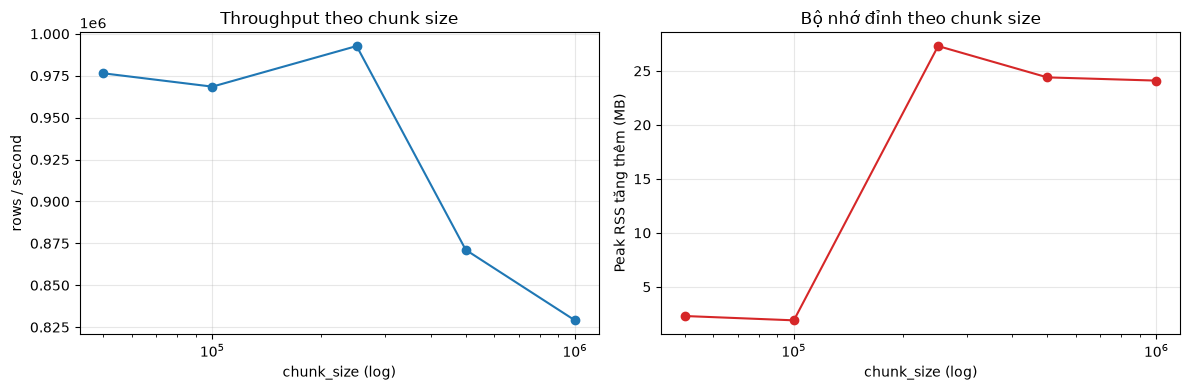

Ngân sách bộ nhớ cho một chunk : 500 MB
RECOMMENDED_CHUNK_SIZE         : 250,000 dòng


In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(chunk_benchmark_df["chunk_size"], chunk_benchmark_df["rows_per_second"], marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("chunk_size (log)")
axes[0].set_ylabel("rows / second")
axes[0].set_title("Throughput theo chunk size")
axes[0].grid(alpha=0.3)

axes[1].plot(chunk_benchmark_df["chunk_size"], chunk_benchmark_df["peak_rss_increase_mb"], marker="o", color="tab:red")
axes[1].set_xscale("log")
axes[1].set_xlabel("chunk_size (log)")
axes[1].set_ylabel("Peak RSS tăng thêm (MB)")
axes[1].set_title("Bộ nhớ đỉnh theo chunk size")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Chọn chunk nhanh nhất trong ngân sách bộ nhớ: tối đa 25% RAM khả dụng hoặc 500 MB (lấy giá trị nhỏ hơn)
MEMORY_BUDGET_MB = min(500, 0.25 * psutil.virtual_memory().available / (1024**2))
eligible = chunk_benchmark_df[chunk_benchmark_df["peak_rss_increase_mb"] <= MEMORY_BUDGET_MB]
if eligible.empty:
    RECOMMENDED_CHUNK_SIZE = int(chunk_benchmark_df.sort_values("peak_rss_increase_mb").iloc[0]["chunk_size"])
    print("Không cấu hình nào nằm trong ngân sách bộ nhớ; chọn cấu hình tốn ít bộ nhớ nhất.")
else:
    RECOMMENDED_CHUNK_SIZE = int(eligible.sort_values("rows_per_second", ascending=False).iloc[0]["chunk_size"])

print(f"Ngân sách bộ nhớ cho một chunk : {MEMORY_BUDGET_MB:.0f} MB")
print(f"RECOMMENDED_CHUNK_SIZE         : {RECOMMENDED_CHUNK_SIZE:,} dòng")

**Đọc kết quả 4.2:** chọn cấu hình có thông lượng cao nhất mà peak RSS vẫn nằm trong ngân sách, vì chunk quá nhỏ làm tăng overhead (nhiều lần gọi `groupby`/ghi file), còn chunk quá lớn làm tăng nguy cơ OOM khi notebook đồng thời giữ nhiều bản sao. Các notebook 01 và 02 đang dùng `100_000` làm giá trị khởi đầu; nếu `RECOMMENDED_CHUNK_SIZE` khác đáng kể, hãy cập nhật hằng số `CHUNK_SIZE` ở đó. Đây là số liệu theo máy của bạn, không phải hằng số của dự án.

### 4.3 Chiến lược xử lý đề xuất

Bảng được tạo từ số liệu thực tế đo ở trên (không ghi cứng).

In [22]:
import pandas as pd
import psutil

available_gb_now = psutil.virtual_memory().available / (1024**3)
SAFE_FRACTION = 0.35   # một DataFrame không nên chiếm quá 35% RAM khả dụng (còn chỗ cho bản sao trung gian)

strategy_records = []
for _, row in memory_estimates_df.iterrows():
    est_gb = row["estimated_dataframe_memory_gb"]
    if est_gb <= SAFE_FRACTION * available_gb_now:
        strategy = "Nạp toàn bộ (pd.read_csv)"
    else:
        strategy = "Chunk processing + aggregate, ghi Parquet"
    strategy_records.append({
        "file": row["file"],
        "estimated_memory_gb": round(est_gb, 3),
        "safe_limit_gb": round(SAFE_FRACTION * available_gb_now, 2),
        "strategy": strategy,
    })

strategy_df = pd.DataFrame(strategy_records)
display(strategy_df)

print(f"Chunk size đề xuất cho train.csv: {RECOMMENDED_CHUNK_SIZE:,} dòng (đo ở 4.2)")
print("Định dạng trung gian đề xuất    : Parquet (giữ dtype, nén tốt; train_cleaned ≈ 1.1 GB theo kết quả 02)")

,file,estimated_memory_gb,safe_limit_gb,strategy
0,train.csv,6.780,0.68,"Chunk processing + aggregate, ghi Parquet"
1,test.csv,0.135,0.68,Nạp toàn bộ (pd.read_csv)
2,sample_submission.csv,0.050,0.68,Nạp toàn bộ (pd.read_csv)
3,transactions.csv,0.003,0.68,Nạp toàn bộ (pd.read_csv)
4,items.csv,0.000,0.68,Nạp toàn bộ (pd.read_csv)
5,holidays_events.csv,0.000,0.68,Nạp toàn bộ (pd.read_csv)
6,oil.csv,0.000,0.68,Nạp toàn bộ (pd.read_csv)
7,stores.csv,0.000,0.68,Nạp toàn bộ (pd.read_csv)


Chunk size đề xuất cho train.csv: 250,000 dòng (đo ở 4.2)
Định dạng trung gian đề xuất    : Parquet (giữ dtype, nén tốt; train_cleaned ≈ 1.1 GB theo kết quả 02)


**Nhu cầu dung lượng đĩa** (ước lượng thô, để chắc chắn pipeline không hết chỗ giữa chừng):

In [23]:
import shutil

raw_gb = sum(p.stat().st_size for p in csv_files) / (1024**3)
processed_gb_estimate = 1.2            # train_cleaned.parquet ≈ 1.1 GB theo kết quả 02
feature_gb_estimate = 3 * processed_gb_estimate   # ước lượng thô cho feature/intermediate
required_gb = raw_gb + processed_gb_estimate + feature_gb_estimate

free_gb = shutil.disk_usage(".").free / (1024**3)

print(f"Raw data           : {raw_gb:6.2f} GB")
print(f"Ước tính cần thêm  : {processed_gb_estimate + feature_gb_estimate:6.2f} GB (processed + feature/intermediate)")
print(f"Tổng nhu cầu       : {required_gb:6.2f} GB")
print(f"Đĩa trống          : {free_gb:6.2f} GB")
print("Disk check:", "PASS" if free_gb > 2 * required_gb else "CHECK — dung lượng trống thấp")

Raw data           :   4.81 GB
Ước tính cần thêm  :   4.80 GB (processed + feature/intermediate)
Tổng nhu cầu       :   9.61 GB
Đĩa trống          :  98.49 GB
Disk check: PASS


## 5. Initial Engineering Decisions

Tổng hợp các kết quả thu được từ Scope, Runtime Environment,
Dataset Inventory và Resource Assessment để đưa ra các quyết định
kỹ thuật ban đầu.

Các quyết định ở đây là provisional và có thể được điều chỉnh
sau Data Validation, EDA và benchmarking.

In [24]:
environment_summary = {
    "python": platform.python_version(),
    "cpu_cores": os.cpu_count(),
    "ram_total_gb": psutil.virtual_memory().total / (1024**3),
    "ram_available_gb": psutil.virtual_memory().available / (1024**3),
    "disk_free_gb": shutil.disk_usage(".").free / (1024**3),
    "num_raw_csv": len(csv_files),
}

environment_summary

{'python': '3.11.16',
 'cpu_cores': 8,
 'ram_total_gb': 7.500282287597656,
 'ram_available_gb': 1.8995208740234375,
 'disk_free_gb': 98.48952102661133,
 'num_raw_csv': 8}

### Initial Engineering Decisions

#### Data Loading
- Không mặc định load toàn bộ raw datasets vào RAM cùng lúc.
- Dataset lớn sẽ được benchmark trước khi quyết định chiến lược loading.
-> RAM tối đa có thể sử dụng giao động từ 1,5GB đến 3GB tùy vào tác vụ đang sử dụng trên máy tính.

#### Memory
- Xem xét dtype optimization cho numerical và categorical columns.
- Sử dụng chunk processing nếu dataset hoặc intermediate dataset
  vượt giới hạn tài nguyên thực tế.
-> **[Hiệu đính]** Bắt buộc chunk processing với `train.csv` (≈ 4.65 GB, ước tính ≈ 6.8 GB khi nạp thành DataFrame, trong khi RAM khả dụng chỉ ≈ 1.5–3.2 GB). `test.csv` và `sample_submission.csv` nhỏ hơn 1 GB nên không cần chunk.

#### Validation
- Vì bài toán có yếu tố thời gian, validation strategy sẽ được
  thiết kế theo temporal ordering thay vì random split.
-> tạm thời đồng ý với kết luận này.

#### Feature Engineering
- Feature engineering sẽ được thực hiện sau khi hoàn thành
  data validation và xác định rõ nguy cơ data leakage.
-> Sẽ cập nhật sau.

#### Modeling
- Model selection sẽ phụ thuộc vào kích thước dữ liệu,
  thời gian training và tài nguyên phần cứng.
-> Sẽ cập nhật sau.

-> Cần cập nhật khi có số liệu thực tế

### 5.1 Decision register

| ID | Quyết định | Trạng thái | Căn cứ |
|---|---|---|---|
| D1 | Không nạp toàn bộ `train.csv` vào RAM; dùng chunk + Parquet | **Confirmed** | 4.65 GB so với RAM khả dụng ≈ 1.5–3.2 GB; mục 4.1 |
| D2 | Validation theo thứ tự thời gian, mô phỏng horizon của test | **Confirmed** (nguyên tắc) | Bài toán forecasting; chi tiết fold để ở notebook modeling |
| D3 | Metric đánh giá: NWRMSLE; huấn luyện trên `log1p(clip(y, 0))` | **Provisional** | Cần đối chiếu đề bài (R1) |
| D4 | Không xóa dòng `unit_sales < 0` ở cleaning; clip khi tính metric | **Confirmed** | 7.795 dòng (0,0062%); metric xử lý âm như 0 |
| D5 | Không impute `onpromotion` thiếu thành `False` | **Confirmed** | Thiếu có cấu trúc (100% đến 2014-03) |
| D6 | Xử lý implicit zeros (dựng panel đầy đủ) | **Informed** (chờ chốt ở 03) | 01 mục 7.9: fill rate 66,4% trong cửa sổ hoạt động; đề xuất ngày vắng = 0 và kiểm chứng bằng validation |
| D7 | Chiến lược cold-start (21,1% cặp trong test) | **Informed** (chờ chốt ở 03) | 01 mục 7.16: 19,56% cặp mới có item đã biết, 1,54% item mới, thêm 7,84% cặp ngừng bán |
| D8 | Chọn mô hình | **Open** | Phụ thuộc kết quả baseline và tài nguyên (CPU, không GPU) |

### 5.2 Environment snapshot

Lưu toàn bộ cấu hình quan trọng vào `reports/00_environment_snapshot.json` để các notebook sau và báo cáo cuối đọc lại, thay vì mỗi notebook tự ghi cứng một bản.

In [25]:
import json
import platform
from datetime import datetime
from pathlib import Path

PROJECT_ROOT = RAW_DATA_DIR.resolve().parents[1]
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)


def to_builtin(value):
    if isinstance(value, dict):
        return {str(k): to_builtin(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_builtin(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if hasattr(value, "isoformat"):
        return value.isoformat()
    return value


snapshot = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "project_name": PROJECT_NAME,
    "task_type": TASK_TYPE,
    "target": TARGET_COLUMN,
    "granularity": ["date", "store_nbr", "item_nbr"],
    "forecast": {
        "start": FORECAST_START,
        "end": FORECAST_END,
        "horizon_days": FORECAST_HORIZON_DAYS,
        "expected_train_end": EXPECTED_TRAIN_END,
        "test_is_full_pair_x_day_grid": is_full_grid,
    },
    "metric": {
        "name": "NWRMSLE",
        "perishable_weight": PERISHABLE_WEIGHT,
        "non_perishable_weight": NON_PERISHABLE_WEIGHT,
        "negative_values_clipped_to_zero": True,
        "status": "provisional - cần đối chiếu đề bài",
    },
    "environment": environment_summary,
    "library_versions": library_versions,
    "seed": SEED,
    "dtype_plan": {k: v[0] for k, v in DTYPE_PLAN.items()},
    "memory": {
        "train_default_gb": default_gb,
        "train_optimized_gb": optimized_gb,
    },
    "chunk": {
        "recommended_chunk_size": RECOMMENDED_CHUNK_SIZE,
        "benchmark_rows": BENCH_ROWS,
        "benchmark": chunk_benchmark_df.to_dict(orient="records"),
    },
    "file_inventory": file_inventory_df.to_dict(orient="records"),
    "dataset_summary": dataset_summary_df.to_dict(orient="records"),
}

snapshot_path = REPORT_DIR / "00_environment_snapshot.json"
with snapshot_path.open("w", encoding="utf-8") as f:
    json.dump(to_builtin(snapshot), f, ensure_ascii=False, indent=2)

print("Đã lưu:", snapshot_path)

Đã lưu: /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast/reports/00_environment_snapshot.json


## Conclusion

Notebook này thiết lập baseline về:

1. Project scope
2. Runtime environment
3. Dataset characteristics
4. Resource constraints
5. Initial engineering decisions

Notebook tiếp theo sẽ sử dụng các kết quả này để thực hiện
Data Understanding & Data Validation trên raw datasets.

Các phần bổ sung (mục 1.1–1.6, 2.1, 4.1–4.3, 5.1–5.2):

6. Định nghĩa bài toán: granularity, forecast horizon, metric đánh giá (NWRMSLE) và hàm kiểm thử.
7. Data dictionary, quan hệ giữa các bảng, tính khả dụng của feature tại thời điểm dự báo (chống leakage).
8. Tái lập môi trường: phiên bản thư viện, random seed, kiểm tra dung lượng đĩa.
9. Kế hoạch dtype, benchmark chunk-size thực tế, chiến lược xử lý đề xuất và snapshot JSON cho các notebook sau.

## Appendix — Resource Assessment Plan (trạng thái thực hiện)

```
Resource Assessment
    ├── Current RAM                      [done]  mục 2 và 4
    ├── Estimated full DataFrame memory  [done]  mục 4
    ├── dtype-optimized memory estimate  [done]  mục 4.1
    ├── Chunk-size benchmark             [done]  mục 4.2
    │   ├── 50k
    │   ├── 100k
    │   ├── 250k
    │   ├── 500k
    │   └── 1M
    └── Recommended processing strategy  [done]  mục 4.3
```

> Trước đây mục này chỉ là sơ đồ kế hoạch (chưa có code benchmark); phần thực thi được bổ sung ở 4.1–4.3.